# Milestone 2: Supervised Pipeline (RQ1)

**Research question.** How much does distance to the nearest fire station raise the probability that a wildfire becomes large ($\geq$100 acres), after accounting for where and when it started?

**Task.** Binary classification. Target `LARGE = 1[FIRE_SIZE >= 100 acres]` (size classes D-G), about 1 positive per 34 negatives.

**Design at a glance**

| Part | Choice | Why |
|---|---|---|
| Validation | train 1992-2016, validate 2017-2018, test 2019-2024 (scored once) | blocks temporal leakage; random k-fold would mix years |
| Spatial check | leave-one-region-out | neighbouring fires are correlated |
| Imbalance | no handling vs class weighting vs undersampling 1:10, compared on validation years | pick the strategy with evidence |
| Models | L2 logistic regression, random forest, LightGBM, XGBoost | 4 algorithm families |
| Feature sets | each model with and without the station features | the gap answers RQ1 |
| Metrics | PR-AUC (primary), ROC-AUC, F1 / precision / recall at a validation-chosen threshold, confusion matrices, per-region results | accuracy is meaningless at 2.5% prevalence |

Data loading and the fire-to-station join live in `src/features.py`; metric and imbalance helpers in `src/modeling.py`. The first run builds a cached feature table (`supervised_learning/cache/`, about 2.5 minutes); later runs read the cache.

In [1]:
import os
import sys
import time
from pathlib import Path

os.environ.setdefault('LOKY_MAX_CPU_COUNT', str(os.cpu_count()))  # silences a joblib core-count warning on Windows

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xgboost as xgb
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def find_repo_root():
    # search this folder and its parents so the notebook runs from anywhere in the repo
    for d in [Path.cwd(), *Path.cwd().parents]:
        if (d / 'src' / 'features.py').is_file():
            return d
    raise FileNotFoundError('repository root (with src/features.py) not found')


ROOT = find_repo_root()
sys.path.insert(0, str(ROOT))
from src.features import load_feature_table
from src.modeling import (best_f1_threshold, block_bootstrap_gain, normalized_confusion, odds_ratio_per_doubling,
                          score, undersample)

%matplotlib inline
sns.set_theme(style='whitegrid', palette='colorblind')
SEED = 281
TRAIN_END, VAL_END = 2016, 2018      # train <= 2016, validate 2017-2018, test 2019-2024
NEG_PER_POS = 10                     # undersampling ratio
CACHE_PATH = ROOT / 'supervised_learning' / 'cache' / 'fire_features.parquet'
FIG_DIR = ROOT / 'supervised_learning' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)


def savefig(name):
    plt.savefig(FIG_DIR / name, dpi=150, bbox_inches='tight')

## 1. Data and temporal split

One row per fire from the FPA-FOD joined to the 52,057 HIFLD fire stations (same join as Milestone 1). Fires on *stacked* coordinates (an exact point shared by 200+ fires, i.e. reporting offices and placeholders) are dropped because their distance to a station is meaningless.

In [2]:
table = load_feature_table(CACHE_PATH, root=ROOT)
data = table[~table['STACKED']].reset_index(drop=True)
data['SPLIT'] = np.select([data['FIRE_YEAR'] <= TRAIN_END, data['FIRE_YEAR'] <= VAL_END], ['train', 'val'], 'test')
train, val, test = (data[data['SPLIT'] == s].reset_index(drop=True) for s in ('train', 'val', 'test'))

split_summary = (data.groupby('SPLIT', sort=False)
                 .agg(years=('FIRE_YEAR', lambda y: f'{y.min()}-{y.max()}'), fires=('LARGE', 'size'),
                      large=('LARGE', 'sum'), share_large=('LARGE', 'mean')))
split_summary['negatives per positive'] = (split_summary['fires'] - split_summary['large']) / split_summary['large']
print(f'{len(table):,} fires loaded, {table.STACKED.sum():,} on stacked locations dropped, {len(data):,} kept')
display(split_summary.style.format({'fires': '{:,}', 'large': '{:,}', 'share_large': '{:.2%}',
                                    'negatives per positive': '{:.1f}'}))

2,661,383 fires loaded, 4,219 on stacked locations dropped, 2,657,164 kept


,years,fires,large,share_large,negatives per positive
SPLIT,,,,,
train,1992-2016,"2,003,788","58,083",2.90%,33.5
val,2017-2018,"164,763","5,043",3.06%,31.7
test,2019-2024,"488,613","12,382",2.53%,38.5


## 2. Features and leakage control

| Group | Columns | Notes |
|---|---|---|
| Where | `LATITUDE`, `LONGITUDE`, `STATE`, `OWNER` | land owner is known at ignition |
| When | `DOY_SIN`, `DOY_COS`, `WEEKDAY`, `DISC_HOUR`, `HOUR_MISSING` | day of year encoded on the circle so Dec 31 and Jan 1 are neighbours |
| Stations | `LOG2_D1..D3` (log2 of km to the 1st/2nd/3rd nearest station + 1), `LOG1P_STATIONS_25KM` | the features under test |

**Excluded on purpose.** `FIRE_SIZE_CLASS` and all containment fields are the outcome; `MTBS_ID` and the ICS-209 IDs exist only for large fires; `FIRE_NAME` is mostly given to large fires; `SOURCE_SYSTEM_TYPE` and `FIRE_YEAR` encode the year, which the temporal split is meant to keep out. None of these is even loaded into the feature table. **Cause** is only known after an investigation, so the main model is a *discovery-time* model without it; section 5 adds cause as a side result.

The station layer is a 2015-2023 snapshot, so older fires are matched to today's stations. That is a measurement limitation, not target leakage: no station feature is computed from fire outcomes.

In [3]:
CONTROLS = ['LATITUDE', 'LONGITUDE', 'STATE', 'OWNER', 'DOY_SIN', 'DOY_COS', 'WEEKDAY', 'DISC_HOUR', 'HOUR_MISSING']
STATION = ['LOG2_D1', 'LOG2_D2', 'LOG2_D3', 'LOG1P_STATIONS_25KM']
FEATURE_SETS = {'base': CONTROLS, 'base + stations': CONTROLS + STATION}
CATEGORICAL = ['STATE', 'OWNER']
TARGET = 'LARGE'

POST_IGNITION = {'FIRE_SIZE', 'LARGE', 'FIRE_SIZE_CLASS', 'CONT_DATE', 'CONT_DOY', 'CONT_TIME', 'MTBS_ID',
                 'ICS_209_PLUS_INCIDENT_JOIN_ID', 'FIRE_NAME', 'SOURCE_SYSTEM_TYPE', 'FIRE_YEAR', 'CAUSE'}
for name, feats in FEATURE_SETS.items():
    assert not POST_IGNITION & set(feats), f'leaky column in {name}'
assert train['FIRE_YEAR'].max() < val['FIRE_YEAR'].min() and val['FIRE_YEAR'].max() < test['FIRE_YEAR'].min()
print('No outcome or year-encoding column in any feature set; train < val < test in time.')

# discovery hour is missing for 31% of fires; check its missingness does not give away the outcome
display(data.groupby(['SPLIT', 'HOUR_MISSING'], sort=False)[TARGET].mean().unstack().rename(
    columns={0: 'hour recorded', 1: 'hour missing'}).style.format('{:.2%}').set_caption('share of large fires'))

No outcome or year-encoding column in any feature set; train < val < test in time.


HOUR_MISSING,hour recorded,hour missing
SPLIT,,
train,3.27%,2.25%
val,3.20%,2.45%
test,2.53%,2.54%


The missing-hour flag is safe to use: large fires are *not* more likely to have a recorded hour (in the test years the large share is the same with or without one), so the flag does not leak the outcome through record completeness.

## 3. Class imbalance: compare strategies on the validation years

Three options on the full feature set, for the two models that train on all 2M rows:

* **none**: plain loss.
* **class weight**: positives up-weighted by $N_{neg}/N_{pos}\approx 33$ (`class_weight='balanced'` / `scale_pos_weight`), i.e. the weighted log-loss $-\sum_i \alpha_{y_i}[y_i\log p_i + (1-y_i)\log(1-p_i)]$ with $\alpha_c = N/(2N_c)$.
* **undersample 1:10**: keep every large fire in the training years and a random 10 small fires per large fire. Validation and test years are never resampled.

SMOTE is not used: 2 of the 13 features are high-cardinality categoricals and 2 are cyclic pairs, where interpolating between two fires produces impossible points, and there is no shortage of real positives (58k). The decision threshold is chosen on the validation years to maximise F1 and then frozen for the test years.

In [4]:
def lgbm_model(scale_pos_weight=1.0, n_estimators=3000):
    return lgb.LGBMClassifier(n_estimators=n_estimators, learning_rate=0.1, num_leaves=63, min_child_samples=100,
                              subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                              scale_pos_weight=scale_pos_weight, verbose=-1, random_state=SEED, n_jobs=-1)


def fit_lgbm(frame, feats, scale_pos_weight=1.0):
    # early stopping on validation PR-AUC; the test years are never seen during fitting
    m = lgbm_model(scale_pos_weight)
    m.fit(frame[feats], frame[TARGET], eval_set=[(val[feats], val[TARGET])], eval_metric='average_precision',
          callbacks=[lgb.early_stopping(100, verbose=False)])
    return m


def fit_logit(frame, feats, class_weight=None):
    cats = [c for c in feats if c in CATEGORICAL]
    nums = [c for c in feats if c not in CATEGORICAL]
    pre = ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=50), cats),
                             ('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), nums)])
    model = make_pipeline(pre, LogisticRegression(C=1.0, class_weight=class_weight, max_iter=2000))
    return model.fit(frame[feats], frame[TARGET])


train_us = undersample(train, TARGET, NEG_PER_POS, SEED)
pos_weight = (train[TARGET] == 0).sum() / train[TARGET].sum()
print(f'undersampled training set: {len(train_us):,} rows ({train_us[TARGET].mean():.1%} large); '
      f'class weight for positives: {pos_weight:.1f}')

STRATEGIES = {'none': (train, False), 'class weight': (train, True), f'undersample 1:{NEG_PER_POS}': (train_us, False)}
feats = FEATURE_SETS['base + stations']
rows = []
for family in ('logistic regression', 'LightGBM'):
    for strategy, (frame, weighted) in STRATEGIES.items():
        start = time.perf_counter()
        if family == 'LightGBM':
            m = fit_lgbm(frame, feats, pos_weight if weighted else 1.0)
        else:
            m = fit_logit(frame, feats, 'balanced' if weighted else None)
        p_val = m.predict_proba(val[feats])[:, 1]
        thr = best_f1_threshold(val[TARGET], p_val)
        rows.append({'family': family, 'strategy': strategy, 'train rows': len(frame),
                     'fit seconds': time.perf_counter() - start, **score(val[TARGET], p_val, thr)})
imbalance = pd.DataFrame(rows).set_index(['family', 'strategy'])
display(imbalance.style.format({'train rows': '{:,}', 'fit seconds': '{:.0f}', 'PR-AUC': '{:.3f}', 'ROC-AUC': '{:.3f}',
                                'F1': '{:.3f}', 'precision': '{:.3f}', 'recall': '{:.3f}', 'threshold': '{:.3f}'})
        .set_caption('validation years 2017-2018, full feature set'))

undersampled training set: 638,913 rows (9.1% large); class weight for positives: 33.5


In [5]:
# rule: highest validation PR-AUC; within 0.005 of the best, prefer the smaller (faster) training set
def pick_strategy(family):
    t = imbalance.loc[family]
    close = t[t['PR-AUC'] >= t['PR-AUC'].max() - 0.005]
    return close.sort_values(['train rows', 'PR-AUC'], ascending=[True, False]).index[0]


CHOSEN = {'logistic regression': pick_strategy('logistic regression'), 'LightGBM': pick_strategy('LightGBM')}
CHOSEN['XGBoost'] = CHOSEN['LightGBM']                 # same loss family as LightGBM
CHOSEN['random forest'] = f'undersample 1:{NEG_PER_POS}'  # a 2M-row forest is too slow; bagging balanced subsets is the standard fix
display(pd.Series(CHOSEN, name='imbalance strategy').to_frame())

,imbalance strategy
logistic regression,undersample 1:10
LightGBM,undersample 1:10
XGBoost,undersample 1:10
random forest,undersample 1:10


**Observations (imbalance).**
- **Undersampling 1:10 is best or tied for both families** (logistic 0.128 vs 0.124 / 0.126; LightGBM 0.249 vs 0.240 / 0.105 validation PR-AUC) while training on a third of the rows, so it is used for every model below.
- **Full class weighting (x33.5) hurt LightGBM badly (0.105).** With positives weighted 33 times, the first trees chase the positives, validation PR-AUC peaks after a few rounds and early stopping ends training almost at once (17 s). A milder weight (for example the square root, x5.8) is worth testing in the tuning phase.
- **The strategies mostly move the probability scale, not the ranking.** The F1-optimal threshold ranges from 0.095 (no handling) to 0.764 (class weight) for the same logistic model, while PR-AUC barely changes. That is why the threshold is re-chosen for every model on the validation years. Probabilities from undersampled models are inflated and should be recalibrated before they are read as real risks.

## 4. Model benchmark: four families, with and without station features

Every model is trained on 1992-2016 with its chosen imbalance strategy, early-stopped (boosted trees) and thresholded on 2017-2018, and scored once on 2019-2024. Hyperparameters are sensible defaults, not tuned; Optuna tuning with time-blocked folds is planned for the optimisation phase.

In [6]:
def training_frame(family):
    return train_us if CHOSEN[family].startswith('undersample') else train


def is_weighted(family):
    return CHOSEN[family] == 'class weight'


def rf_matrix(frame, feats):
    # random forest needs numbers: categories -> integer codes (shared category list across splits), missing hour -> -1
    X = frame[feats].copy()
    for c in set(feats) & set(CATEGORICAL):
        X[c] = X[c].cat.codes
    X['DISC_HOUR'] = X['DISC_HOUR'].fillna(-1)
    return X


def fit_family(family, feats):
    frame = training_frame(family)
    if family == 'logistic regression':
        m = fit_logit(frame, feats, 'balanced' if is_weighted(family) else None)
        return m, lambda d: m.predict_proba(d[feats])[:, 1]
    if family == 'random forest':
        m = RandomForestClassifier(n_estimators=300, min_samples_leaf=20, max_features='sqrt', n_jobs=-1,
                                   random_state=SEED).fit(rf_matrix(frame, feats), frame[TARGET])
        return m, lambda d: m.predict_proba(rf_matrix(d, feats))[:, 1]
    if family == 'LightGBM':
        m = fit_lgbm(frame, feats, pos_weight if is_weighted(family) else 1.0)
        return m, lambda d: m.predict_proba(d[feats])[:, 1]
    m = xgb.XGBClassifier(n_estimators=3000, learning_rate=0.1, max_depth=8, min_child_weight=5, subsample=0.8,
                          colsample_bytree=0.8, tree_method='hist', enable_categorical=True, eval_metric='aucpr',
                          early_stopping_rounds=100, scale_pos_weight=pos_weight if is_weighted(family) else 1.0,
                          n_jobs=-1, random_state=SEED)
    m.fit(frame[feats], frame[TARGET], eval_set=[(val[feats], val[TARGET])], verbose=False)
    return m, lambda d: m.predict_proba(d[feats])[:, 1]


FAMILIES = ['logistic regression', 'random forest', 'LightGBM', 'XGBoost']
models, prob_val, prob_test, thresholds, fit_time = {}, {}, {}, {}, {}
for family in FAMILIES:
    for set_name, feats in FEATURE_SETS.items():
        key = (family, set_name)
        start = time.perf_counter()
        models[key], predict = fit_family(family, feats)
        fit_time[key] = time.perf_counter() - start
        prob_val[key], prob_test[key] = predict(val), predict(test)
        thresholds[key] = best_f1_threshold(val[TARGET], prob_val[key])
        print(f'{family:20s} {set_name:16s} fitted in {fit_time[key]:5.0f}s, '
              f'val PR-AUC {average_precision_score(val[TARGET], prob_val[key]):.3f}')

logistic regression  base             fitted in     4s, val PR-AUC 0.093


logistic regression  base + stations  fitted in     5s, val PR-AUC 0.128


random forest        base             fitted in   240s, val PR-AUC 0.229


random forest        base + stations  fitted in   322s, val PR-AUC 0.227


LightGBM             base             fitted in     9s, val PR-AUC 0.236


LightGBM             base + stations  fitted in    14s, val PR-AUC 0.249


XGBoost              base             fitted in    45s, val PR-AUC 0.228


XGBoost              base + stations  fitted in    55s, val PR-AUC 0.248


In [7]:
y_test = test[TARGET].to_numpy()
bench = pd.DataFrame([{'family': f, 'features': s, 'val PR-AUC': average_precision_score(val[TARGET], prob_val[(f, s)]),
                       **score(y_test, prob_test[(f, s)], thresholds[(f, s)])} for f, s in models])
bench = bench.set_index(['family', 'features'])
gain = bench['PR-AUC'].xs('base + stations', level='features') - bench['PR-AUC'].xs('base', level='features')
print(f'no-skill PR-AUC on the test years = prevalence = {y_test.mean():.3f}')
display(bench.style.format('{:.3f}').highlight_max(subset=['PR-AUC', 'ROC-AUC', 'F1'], color='#cde8cd')
        .set_caption('test years 2019-2024 (threshold chosen on 2017-2018)'))
display(pd.DataFrame({'PR-AUC gain from stations': gain,
                      'relative gain': gain / bench['PR-AUC'].xs('base', level='features')})
        .style.format({'PR-AUC gain from stations': '{:+.3f}', 'relative gain': '{:+.0%}'}))

no-skill PR-AUC on the test years = prevalence = 0.025


,PR-AUC gain from stations,relative gain
family,,
logistic regression,+0.039,+49%
random forest,+0.048,+36%
LightGBM,+0.026,+20%
XGBoost,+0.041,+34%


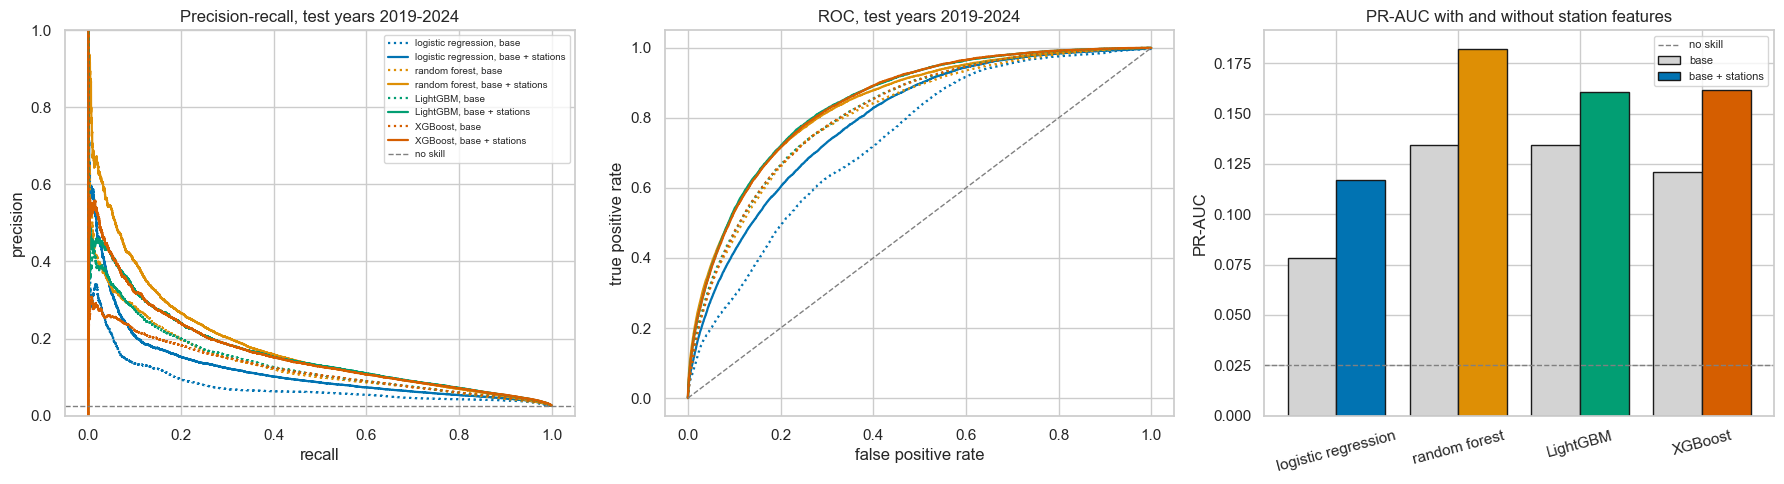

In [8]:
colors = dict(zip(FAMILIES, sns.color_palette('colorblind', len(FAMILIES))))
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for (family, set_name), p in prob_test.items():
    style = dict(color=colors[family], ls='-' if set_name == 'base + stations' else ':', lw=1.6)
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[0].plot(rec, prec, label=f'{family}, {set_name}', **style)
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[1].plot(fpr, tpr, **style)
axes[0].axhline(y_test.mean(), color='gray', ls='--', lw=1, label='no skill')
axes[0].set(xlabel='recall', ylabel='precision', title='Precision-recall, test years 2019-2024', ylim=(0, 1))
axes[0].legend(fontsize=7)
axes[1].plot([0, 1], [0, 1], color='gray', ls='--', lw=1)
axes[1].set(xlabel='false positive rate', ylabel='true positive rate', title='ROC, test years 2019-2024')

pr = bench['PR-AUC'].unstack('features').loc[FAMILIES]
x = np.arange(len(FAMILIES))
axes[2].bar(x - 0.2, pr['base'], 0.4, label='base', color='lightgray', edgecolor='k')
axes[2].bar(x + 0.2, pr['base + stations'], 0.4, label='base + stations', color=[colors[f] for f in FAMILIES],
            edgecolor='k')
axes[2].axhline(y_test.mean(), color='gray', ls='--', lw=1, label='no skill')
axes[2].set_xticks(x, FAMILIES, rotation=15)
axes[2].set(ylabel='PR-AUC', title='PR-AUC with and without station features')
axes[2].legend(fontsize=8)
plt.tight_layout()
savefig('benchmark_curves.png')
plt.show()

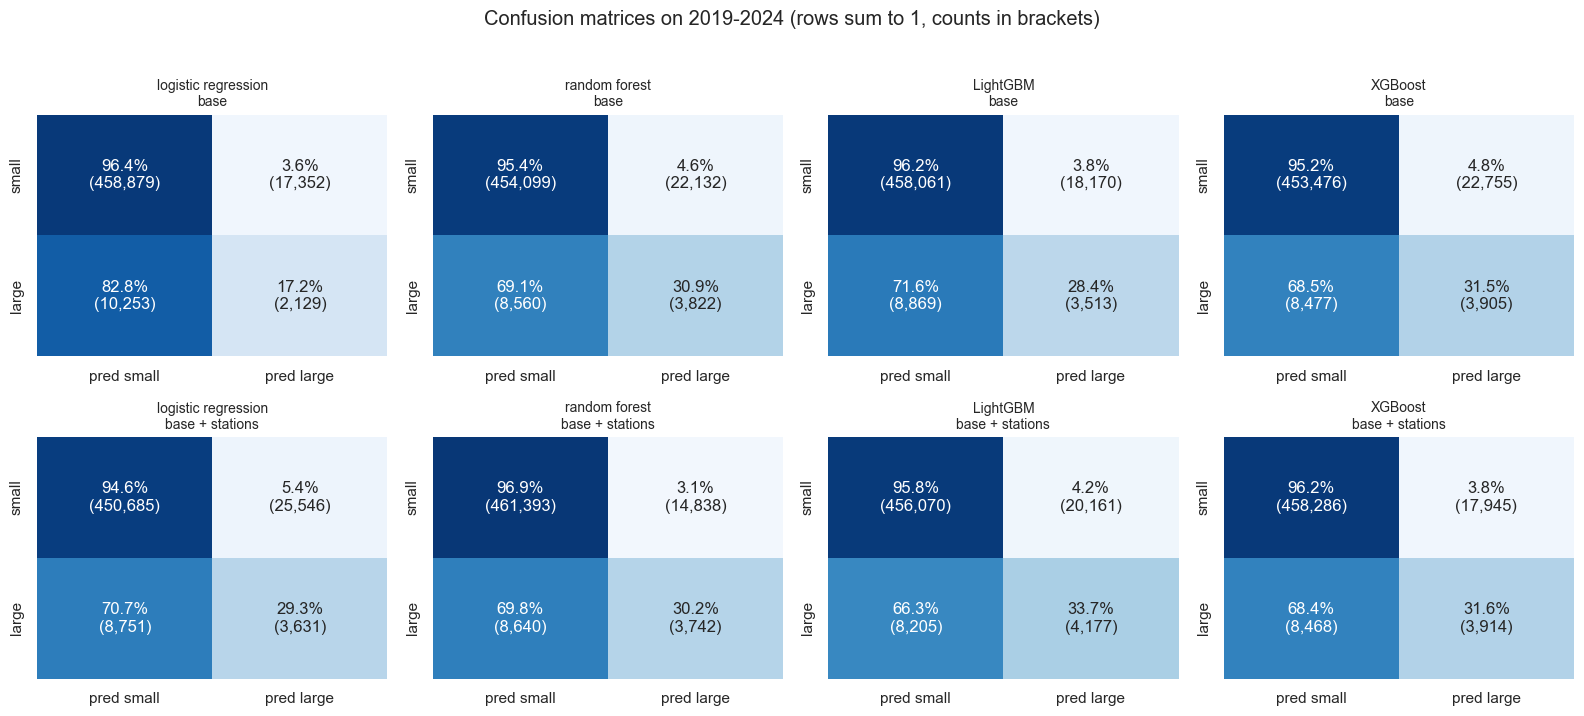

In [9]:
fig, axes = plt.subplots(2, len(FAMILIES), figsize=(4 * len(FAMILIES), 7))
for j, family in enumerate(FAMILIES):
    for i, set_name in enumerate(FEATURE_SETS):
        key = (family, set_name)
        cm = normalized_confusion(y_test, prob_test[key], thresholds[key])
        counts = pd.crosstab(y_test, (prob_test[key] >= thresholds[key]).astype(int)).reindex(
            index=[0, 1], columns=[0, 1], fill_value=0).to_numpy()
        labels = np.array([[f'{cm[r, c]:.1%}\n({counts[r, c]:,})' for c in range(2)] for r in range(2)])
        sns.heatmap(cm, annot=labels, fmt='', cmap='Blues', vmin=0, vmax=1, cbar=False, ax=axes[i, j],
                    xticklabels=['pred small', 'pred large'], yticklabels=['small', 'large'])
        axes[i, j].set_title(f'{family}\n{set_name}', fontsize=10)
plt.suptitle('Confusion matrices on 2019-2024 (rows sum to 1, counts in brackets)', y=1.02)
plt.tight_layout()
savefig('confusion_matrices.png')
plt.show()

**Observations (benchmark).**
- **Station features improve every family on the test years:** logistic 0.078 to 0.117, random forest 0.134 to 0.182, LightGBM 0.134 to 0.161, XGBoost 0.121 to 0.162 PR-AUC. ROC-AUC of the tree models rises from 0.81-0.82 to 0.84-0.85.
- **Best model: random forest with stations (PR-AUC 0.182, F1 0.242)**, about 7 times the no-skill 0.025. The boosted trees are close behind (0.161-0.162). The trees beat logistic regression by a wide margin because latitude, longitude and state interact in ways a linear model cannot represent; logistic regression still gains the most in relative terms (+49%), since log distance enters linearly, as the EDA suggested.
- **Validation and test disagree.** Validation PR-AUC is about 0.25, test about 0.16, and the ranking changes (random forest is last on validation, first on test). The test years have fewer large fires (2.5% vs 3.1%) and include the 2020-21 reporting changes. Choosing models on a single two-year window is therefore fragile; the tuning phase will use several time-blocked folds.
- **The random forest's station gain shows up only on the test years** (validation 0.229 to 0.227, test +0.048). This fits the Milestone 1 finding, confirmed by the odds ratios below, that the distance signal is stronger in recent years.
- **Confusion matrices:** at the F1 threshold the tree models catch 30-34% of large fires while flagging only 3-5% of small ones. About 1 in 5 flagged fires becomes large, against 1 in 40 by chance. Adding stations to LightGBM raises recall from 28.4% to 33.7% at almost the same false-positive rate.

## 5. How much do the station features add? Uncertainty, cause, and effect size

**Bootstrap interval for the gain.** Fires in the same state and year share weather and reporting practice, so resampling single fires would understate the uncertainty. We resample whole state-by-year blocks of the test set (about 300 blocks) and recompute the PR-AUC gain.

In [10]:
blocks = (test['STATE'].astype(str) + '_' + test['FIRE_YEAR'].astype(str)).to_numpy()
N_BOOT = 200
boot = {f: block_bootstrap_gain(y_test, prob_test[(f, 'base')], prob_test[(f, 'base + stations')], blocks,
                                N_BOOT, SEED) for f in FAMILIES}
gain_ci = pd.DataFrame({f: {'gain': gain[f], 'ci_low': np.percentile(g, 2.5), 'ci_high': np.percentile(g, 97.5),
                            'share of resamples > 0': (g > 0).mean()} for f, g in boot.items()}).T
print(f'{len(np.unique(blocks))} state-year blocks, {N_BOOT} resamples')
display(gain_ci.style.format({'gain': '{:+.3f}', 'ci_low': '{:+.3f}', 'ci_high': '{:+.3f}',
                              'share of resamples > 0': '{:.0%}'}))

315 state-year blocks, 200 resamples


,gain,ci_low,ci_high,share of resamples > 0
logistic regression,+0.039,+0.028,+0.052,100%
random forest,+0.048,+0.027,+0.063,100%
LightGBM,+0.026,+0.019,+0.033,100%
XGBoost,+0.041,+0.029,+0.051,100%


**Adding cause.** Cause class (human / natural / missing) is only known after an investigation, so it cannot be used when a fire is reported. Adding it to LightGBM shows whether the station signal is just a proxy for cause (lightning fires are remote).

In [11]:
rows = []
for set_name, feats in FEATURE_SETS.items():
    with_cause = feats + ['CAUSE']
    m = fit_lgbm(training_frame('LightGBM'), with_cause, pos_weight if is_weighted('LightGBM') else 1.0)
    p = m.predict_proba(test[with_cause])[:, 1]
    rows.append({'features': f'{set_name} + cause', 'PR-AUC': average_precision_score(y_test, p),
                 'PR-AUC without cause': bench.loc[('LightGBM', set_name), 'PR-AUC']})
cause_table = pd.DataFrame(rows).set_index('features')
display(cause_table.style.format('{:.3f}').set_caption('LightGBM, test years'))

,PR-AUC,PR-AUC without cause
features,,
base + cause,0.120,0.134
base + stations + cause,0.154,0.161


**Effect size (the RQ1 number).** Prediction metrics say *whether* distance helps; an odds ratio says *by how much*. An unpenalised logistic regression of `LARGE` on $\log_2(d_1+1)$, adjusted for state, land owner, season (`DOY_SIN`, `DOY_COS`) and year, gives the odds ratio per doubling of distance, fitted separately on the training and the test years (300k-fire samples, 95% Wald intervals).

In [12]:
OR_SAMPLE = 300_000
or_rows = {}
for label, frame in [('train years 1992-2016', train), ('test years 2019-2024', test)]:
    or_rows[(label, 'unadjusted')] = odds_ratio_per_doubling(frame, TARGET, 'LOG2_D1', [], [], OR_SAMPLE, SEED)
    or_rows[(label, 'adjusted')] = odds_ratio_per_doubling(frame, TARGET, 'LOG2_D1', ['STATE', 'OWNER'],
                                                           ['DOY_SIN', 'DOY_COS', 'FIRE_YEAR'], OR_SAMPLE, SEED)
odds = pd.DataFrame(or_rows).T
display(odds.style.format({'odds_ratio': '{:.2f}', 'ci_low': '{:.2f}', 'ci_high': '{:.2f}', 'n': '{:,.0f}'}))

**Observations (station effect).**
- **The gain is not noise.** The 95% block-bootstrap interval excludes zero for every family (LightGBM +0.019 to +0.033, random forest +0.027 to +0.063), and all 200 resamples are positive for all four.
- **Distance is not a stand-in for cause.** Adding cause *lowers* LightGBM's test PR-AUC (0.134 to 0.120 without stations, 0.161 to 0.154 with them), as in Milestone 1: the share of fires with a missing cause changes over time, so cause does not transfer well to the test years. With cause in the model, the station features still add +0.034.
- **Effect size.** Adjusted for state, land owner, season and year, each doubling of distance multiplies the odds of a large fire by **1.78 (1.74-1.83) in the training years**, matching the 1.80 of Milestone 1, and by **2.08 (2.03-2.14) in the test years**. Going from 2 km to 32 km (four doublings) multiplies the odds by roughly 1.78^4, about 10. The stronger recent effect again fits the station layer describing recent years best.

## 6. Localised evaluation: per region, and with whole regions held out

**Per-region test results** for LightGBM. PR-AUC must be read against each region's own prevalence, so the table also shows the *lift* (PR-AUC / prevalence). The confusion counts use the single threshold chosen on the validation years.

In [13]:
rows = []
for region, idx in test.groupby('REGION', observed=True).groups.items():
    y = y_test[idx]
    if y.sum() < 30:
        continue
    row = {'region': region, 'fires': len(idx), 'prevalence': y.mean()}
    for set_name in FEATURE_SETS:
        key = ('LightGBM', set_name)
        row[f'PR-AUC {set_name}'] = average_precision_score(y, prob_test[key][idx])
    key = ('LightGBM', 'base + stations')
    pred = prob_test[key][idx] >= thresholds[key]
    row.update({'TP': int((pred & (y == 1)).sum()), 'FP': int((pred & (y == 0)).sum()),
                'FN': int((~pred & (y == 1)).sum()), 'TN': int((~pred & (y == 0)).sum())})
    rows.append(row)
by_region = pd.DataFrame(rows).set_index('region').sort_values('prevalence', ascending=False)
by_region['gain'] = by_region['PR-AUC base + stations'] - by_region['PR-AUC base']
by_region['lift'] = by_region['PR-AUC base + stations'] / by_region['prevalence']
by_region['recall'] = by_region['TP'] / (by_region['TP'] + by_region['FN'])
by_region['precision'] = by_region['TP'] / (by_region['TP'] + by_region['FP']).clip(lower=1)
display(by_region.style.format({'fires': '{:,}', 'prevalence': '{:.2%}', 'PR-AUC base': '{:.3f}',
                                'PR-AUC base + stations': '{:.3f}', 'gain': '{:+.3f}', 'lift': '{:.1f}x',
                                'TP': '{:,}', 'FP': '{:,}', 'FN': '{:,}', 'TN': '{:,}', 'recall': '{:.1%}',
                                'precision': '{:.1%}'}))

,fires,prevalence,PR-AUC base,PR-AUC base + stations,TP,FP,FN,TN,gain,lift,recall,precision
region,,,,,,,,,,,,
Alaska,"2,772",20.13%,0.458,0.561,511,745,47,"1,469",+0.103,2.8x,91.6%,40.7%
Plains,"74,293",4.59%,0.154,0.187,"1,870","10,613","1,538","60,272",+0.033,4.1x,54.9%,15.0%
Southwest,"25,285",4.04%,0.140,0.159,211,908,811,"23,355",+0.019,3.9x,20.6%,18.9%
HI/PR,"2,023",3.36%,0.238,0.253,23,54,45,"1,901",+0.015,7.5x,33.8%,29.9%
Mountain West,"71,648",3.08%,0.111,0.135,799,"4,553","1,405","64,891",+0.024,4.4x,36.3%,14.9%
Pacific,"69,123",2.37%,0.096,0.113,236,866,"1,402","66,619",+0.017,4.8x,14.4%,21.4%
Southeast,"126,578",2.16%,0.126,0.133,406,"1,497","2,326","122,349",+0.007,6.2x,14.9%,21.3%
North/East,"116,891",0.64%,0.072,0.079,121,925,631,"115,214",+0.007,12.3x,16.1%,11.6%


**Leave-one-region-out.** Random splits leak through spatial autocorrelation, and even a temporal split lets the model memorise each place. Here LightGBM is trained on the training years of every *other* region and scored on the test years of the held-out region, so the model has never seen that region at all. `STATE` is dropped (every held-out state would be unseen); latitude and longitude stay. For speed this check uses the undersampled training set and a fixed 400 trees.

,test fires,prevalence,PR-AUC base,PR-AUC base + stations,gain
held-out region,,,,,
Alaska,"2,772",20.13%,0.233,0.394,+0.161
Plains,"74,293",4.59%,0.083,0.139,+0.056
Southwest,"25,285",4.04%,0.076,0.103,+0.027
HI/PR,"2,023",3.36%,0.233,0.081,-0.152
Mountain West,"71,648",3.08%,0.051,0.087,+0.036
Pacific,"69,123",2.37%,0.028,0.050,+0.021
Southeast,"126,578",2.16%,0.038,0.045,+0.007
North/East,"116,891",0.64%,0.033,0.033,+0.001


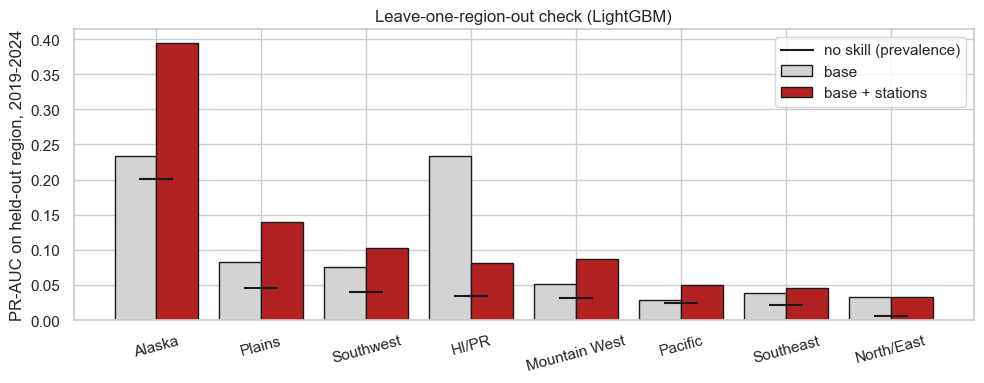

In [14]:
SPATIAL_SETS = {name: [f for f in feats if f != 'STATE'] for name, feats in FEATURE_SETS.items()}
rows = []
for region in by_region.index:
    tr = train_us[train_us['REGION'] != region]
    te = test[test['REGION'] == region]
    row = {'held-out region': region, 'test fires': len(te), 'prevalence': te[TARGET].mean()}
    for set_name, feats in SPATIAL_SETS.items():
        m = lgbm_model(n_estimators=400).fit(tr[feats], tr[TARGET])
        row[f'PR-AUC {set_name}'] = average_precision_score(te[TARGET], m.predict_proba(te[feats])[:, 1])
    rows.append(row)
spatial = pd.DataFrame(rows).set_index('held-out region')
spatial['gain'] = spatial['PR-AUC base + stations'] - spatial['PR-AUC base']
display(spatial.style.format({'test fires': '{:,}', 'prevalence': '{:.2%}', 'PR-AUC base': '{:.3f}',
                              'PR-AUC base + stations': '{:.3f}', 'gain': '{:+.3f}'}))

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(spatial))
ax.bar(x - 0.2, spatial['PR-AUC base'], 0.4, label='base', color='lightgray', edgecolor='k')
ax.bar(x + 0.2, spatial['PR-AUC base + stations'], 0.4, label='base + stations', color='firebrick', edgecolor='k')
ax.scatter(x, spatial['prevalence'], marker='_', s=600, color='k', zorder=3, label='no skill (prevalence)')
ax.set_xticks(x, spatial.index, rotation=15)
ax.set(ylabel='PR-AUC on held-out region, 2019-2024', title='Leave-one-region-out check (LightGBM)')
ax.legend()
plt.tight_layout()
savefig('spatial_holdout.png')
plt.show()

**Observations (localised).**
- **The gain is positive in all 8 regions** and largest where stations are sparse and fires grow: Alaska +0.103, Plains +0.033, Mountain West +0.024. It is smallest in the Southeast and North/East (+0.007), where stations are dense and distance varies little.
- **One national threshold behaves very differently by region.** Recall is 92% in Alaska and 55% in the Plains but only 14-16% in the Pacific, Southeast and North/East. Region-specific thresholds are a cheap improvement for the optimisation phase.
- **The distance effect transfers to regions the model has never seen.** With a whole region held out, the station features raise PR-AUC in 7 of 8 regions (Alaska +0.161, Plains +0.056, Mountain West +0.036), so the model is learning a general distance relationship, not memorising places. Absolute PR-AUC falls when the region is unseen (Pacific 0.113 to 0.050), which shows how much the main model relies on knowing each location.
- **Exceptions.** HI/PR drops (-0.152), but it has only 68 large test fires and island geography unlike anything in the training regions, so its numbers are unstable. North/East shows no gain (+0.001) at 0.6% prevalence.

## 7. What the model learned about distance (SHAP)

LightGBM computes exact TreeSHAP values natively (`pred_contrib=True`), so no extra package is needed. Values are in log-odds; positive means the feature pushes the fire towards *large*. We use a random 100k sample of test fires.

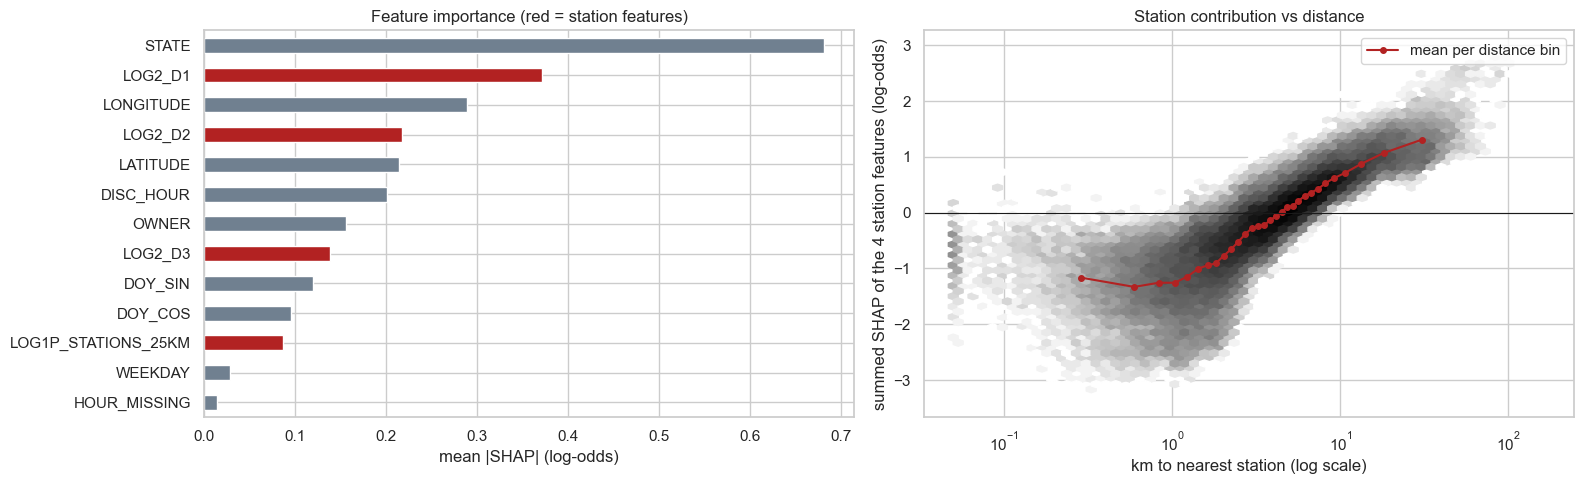

station contribution: -1.16 log-odds in the nearest bin, +1.31 in the farthest (odds x11.8 from nearest to farthest)


In [15]:
lgbm = models[('LightGBM', 'base + stations')]
feats = FEATURE_SETS['base + stations']
sample = test.sample(100_000, random_state=SEED)
contrib = lgbm.booster_.predict(sample[feats], pred_contrib=True)
shap_df = pd.DataFrame(contrib[:, :-1], columns=feats, index=sample.index)   # last column is the bias term

importance = shap_df.abs().mean().sort_values()
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
importance.plot.barh(ax=axes[0], color=['firebrick' if f in STATION else 'slategray' for f in importance.index])
axes[0].set(xlabel='mean |SHAP| (log-odds)', title='Feature importance (red = station features)')

d1 = sample['D1_KM'].clip(lower=0.05)
station_effect = shap_df[STATION].sum(axis=1)
axes[1].hexbin(d1, station_effect, xscale='log', gridsize=60, bins='log', cmap='Greys', mincnt=1)
bins = pd.qcut(d1, 30, duplicates='drop')
curve = station_effect.groupby(bins, observed=True).mean()
axes[1].plot(d1.groupby(bins, observed=True).median(), curve, color='firebrick', marker='o', ms=4,
             label='mean per distance bin')
axes[1].axhline(0, color='k', lw=0.8)
axes[1].set(xlabel='km to nearest station (log scale)', ylabel='summed SHAP of the 4 station features (log-odds)',
            title='Station contribution vs distance')
axes[1].legend()
plt.tight_layout()
savefig('shap_distance.png')
plt.show()

near, far = curve.iloc[0], curve.iloc[-1]
print(f'station contribution: {near:+.2f} log-odds in the nearest bin, {far:+.2f} in the farthest '
      f'(odds x{np.exp(far - near):.1f} from nearest to farthest)')

**Observations (SHAP).**
- **Nearest-station distance (`LOG2_D1`) is the second most important feature**, after `STATE`. Taken together, the four station features contribute more than `STATE` (summed mean |SHAP| about 0.81 vs 0.68 log-odds).
- **The shape matches the EDA.** The station contribution is flat below about 1 km, then rises almost linearly in log distance; it crosses zero near 4 km (the median fire) and keeps rising past 30 km. Within a kilometre, being closer does not help further, probably because dispatch time, not travel time, dominates there.
- **Size of the effect.** From the nearest to the farthest distance bin, the station features move the odds of a large fire by about x12, in line with the adjusted odds ratio over the same range.

## 8. Summary and next steps

**Answer to RQ1 (preliminary).** Distance to the nearest fire station carries real, transferable information about whether a fire becomes large. After adjusting for state, land owner, season and year, each doubling of distance raises the odds of a 100+ acre fire by about 1.8 times (2.1 in 2019-2024). Adding station features to discovery-time models raises test PR-AUC in all four model families (by +0.026 to +0.048, all bootstrap intervals above zero), in all eight regions, and in 7 of 8 regions the model never saw during training.

**What the pipeline covers**

| Requirement | Where |
|---|---|
| Leakage-free validation | temporal train / validation / test split (section 1), leakage assertions (section 2), leave-one-region-out (section 6) |
| Class imbalance | none vs class weight vs undersampling, compared on validation years; F1 threshold chosen on validation (section 3) |
| Three or more model families | logistic regression, random forest, LightGBM, XGBoost (section 4) |
| Informative metrics | PR-AUC, ROC-AUC, F1 / precision / recall, PR and ROC curves, confusion matrices, per-region tables (sections 4-6) |

**Limitations.** The station layer is a recent snapshot of mostly structural stations, so federal wildland crews are missing and older fires are matched to today's stations. Weather and fuel, which drive final size, are not in the data, which caps absolute PR-AUC. The probabilities of the undersampled models are not calibrated.

**Next steps (optimisation phase).**
1. Tune LightGBM, XGBoost and random forest with Optuna on expanding time-blocked folds inside 1992-2018, then refit on all of 1992-2018 before the final test.
2. Try milder class weights and calibrate probabilities (isotonic, on validation years).
3. Region-specific thresholds.
4. More engineered features: past-years fire density and large-fire rate per grid cell (computed only from earlier years), and distance to wildland-agency stations.
5. A matched comparison of fires in the same cell, season and cause at different distances, as a second estimate of the effect.